In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv('Brain_Tumor_Prediction_Dataset.csv')
df.head()

,Age,Gender,Country,Tumor_Size,Tumor_Location,MRI_Findings,Genetic_Risk,Smoking_History,Alcohol_Consumption,Radiation_Exposure,...,Chronic_Illness,Blood_Pressure,Diabetes,Tumor_Type,Treatment_Received,Survival_Rate(%),Tumor_Growth_Rate,Family_History,Symptom_Severity,Brain_Tumor_Present
0,66,Other,China,8.70,Cerebellum,Severe,81,No,Yes,Medium,...,Yes,122/88,No,Malignant,NaN,58,Slow,Yes,Mild,No
1,87,Female,Australia,8.14,Temporal,Normal,65,No,Yes,Medium,...,No,126/119,No,Malignant,NaN,13,Rapid,Yes,Severe,No
2,41,Male,Canada,6.02,Occipital,Severe,100,Yes,No,Low,...,No,118/65,No,Benign,Chemotherapy,67,Slow,Yes,Moderate,Yes
3,52,Male,Japan,7.26,Occipital,Normal,19,Yes,Yes,High,...,No,165/119,Yes,Benign,Radiation,85,Moderate,No,Moderate,Yes
4,84,Female,Brazil,7.94,Temporal,Abnormal,47,No,Yes,Medium,...,Yes,156/97,Yes,Malignant,NaN,17,Moderate,No,Moderate,No


In [3]:
df.tail()

,Age,Gender,Country,Tumor_Size,Tumor_Location,MRI_Findings,Genetic_Risk,Smoking_History,Alcohol_Consumption,Radiation_Exposure,...,Chronic_Illness,Blood_Pressure,Diabetes,Tumor_Type,Treatment_Received,Survival_Rate(%),Tumor_Growth_Rate,Family_History,Symptom_Severity,Brain_Tumor_Present
249995,77,Female,Germany,2.05,Frontal,Normal,9,Yes,Yes,High,...,No,93/80,Yes,Benign,Chemotherapy,36,Rapid,Yes,Mild,No
249996,89,Other,Japan,3.55,Parietal,Normal,75,Yes,No,Low,...,Yes,119/112,Yes,Benign,Radiation,80,Slow,Yes,Moderate,Yes
249997,16,Other,Russia,8.54,Temporal,Normal,52,No,Yes,Low,...,Yes,101/68,Yes,Malignant,Radiation,72,Slow,No,Severe,Yes
249998,56,Other,Germany,2.17,Cerebellum,Severe,95,Yes,No,High,...,No,179/106,Yes,Benign,NaN,83,Rapid,Yes,Moderate,Yes
249999,54,Female,Australia,5.19,Parietal,Abnormal,83,Yes,No,Medium,...,No,147/82,Yes,Malignant,Radiation,94,Slow,No,Mild,No


In [5]:
df.shape

(250000, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Age                  250000 non-null  int64  
 1   Gender               250000 non-null  object 
 2   Country              250000 non-null  object 
 3   Tumor_Size           250000 non-null  float64
 4   Tumor_Location       250000 non-null  object 
 5   MRI_Findings         250000 non-null  object 
 6   Genetic_Risk         250000 non-null  int64  
 7   Smoking_History      250000 non-null  object 
 8   Alcohol_Consumption  250000 non-null  object 
 9   Radiation_Exposure   250000 non-null  object 
 10  Head_Injury_History  250000 non-null  object 
 11  Chronic_Illness      250000 non-null  object 
 12  Blood_Pressure       250000 non-null  object 
 13  Diabetes             250000 non-null  object 
 14  Tumor_Type           250000 non-null  object 
 15  Treatment_Receive

In [7]:
df.dtypes

,0
Age,int64
Gender,object
Country,object
Tumor_Size,float64
Tumor_Location,object
MRI_Findings,object
Genetic_Risk,int64
Smoking_History,object
Alcohol_Consumption,object
Radiation_Exposure,object


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,250000.0,46.962424,24.517143,5.0,26.00,47.00,68.00,89.0
Tumor_Size,250000.0,5.251768,2.742576,0.5,2.87,5.26,7.63,10.0
Genetic_Risk,250000.0,49.998916,29.178031,0.0,25.00,50.00,75.00,100.0
Survival_Rate(%),250000.0,54.481532,25.999932,10.0,32.00,55.00,77.00,99.0


In [9]:
df.nunique()

,0
Age,85
Gender,3
Country,12
Tumor_Size,951
Tumor_Location,5
MRI_Findings,3
Genetic_Risk,101
Smoking_History,2
Alcohol_Consumption,2
Radiation_Exposure,3


array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Tumor_Size'}>],
       [<Axes: title={'center': 'Genetic_Risk'}>,
        <Axes: title={'center': 'Survival_Rate(%)'}>]], dtype=object)

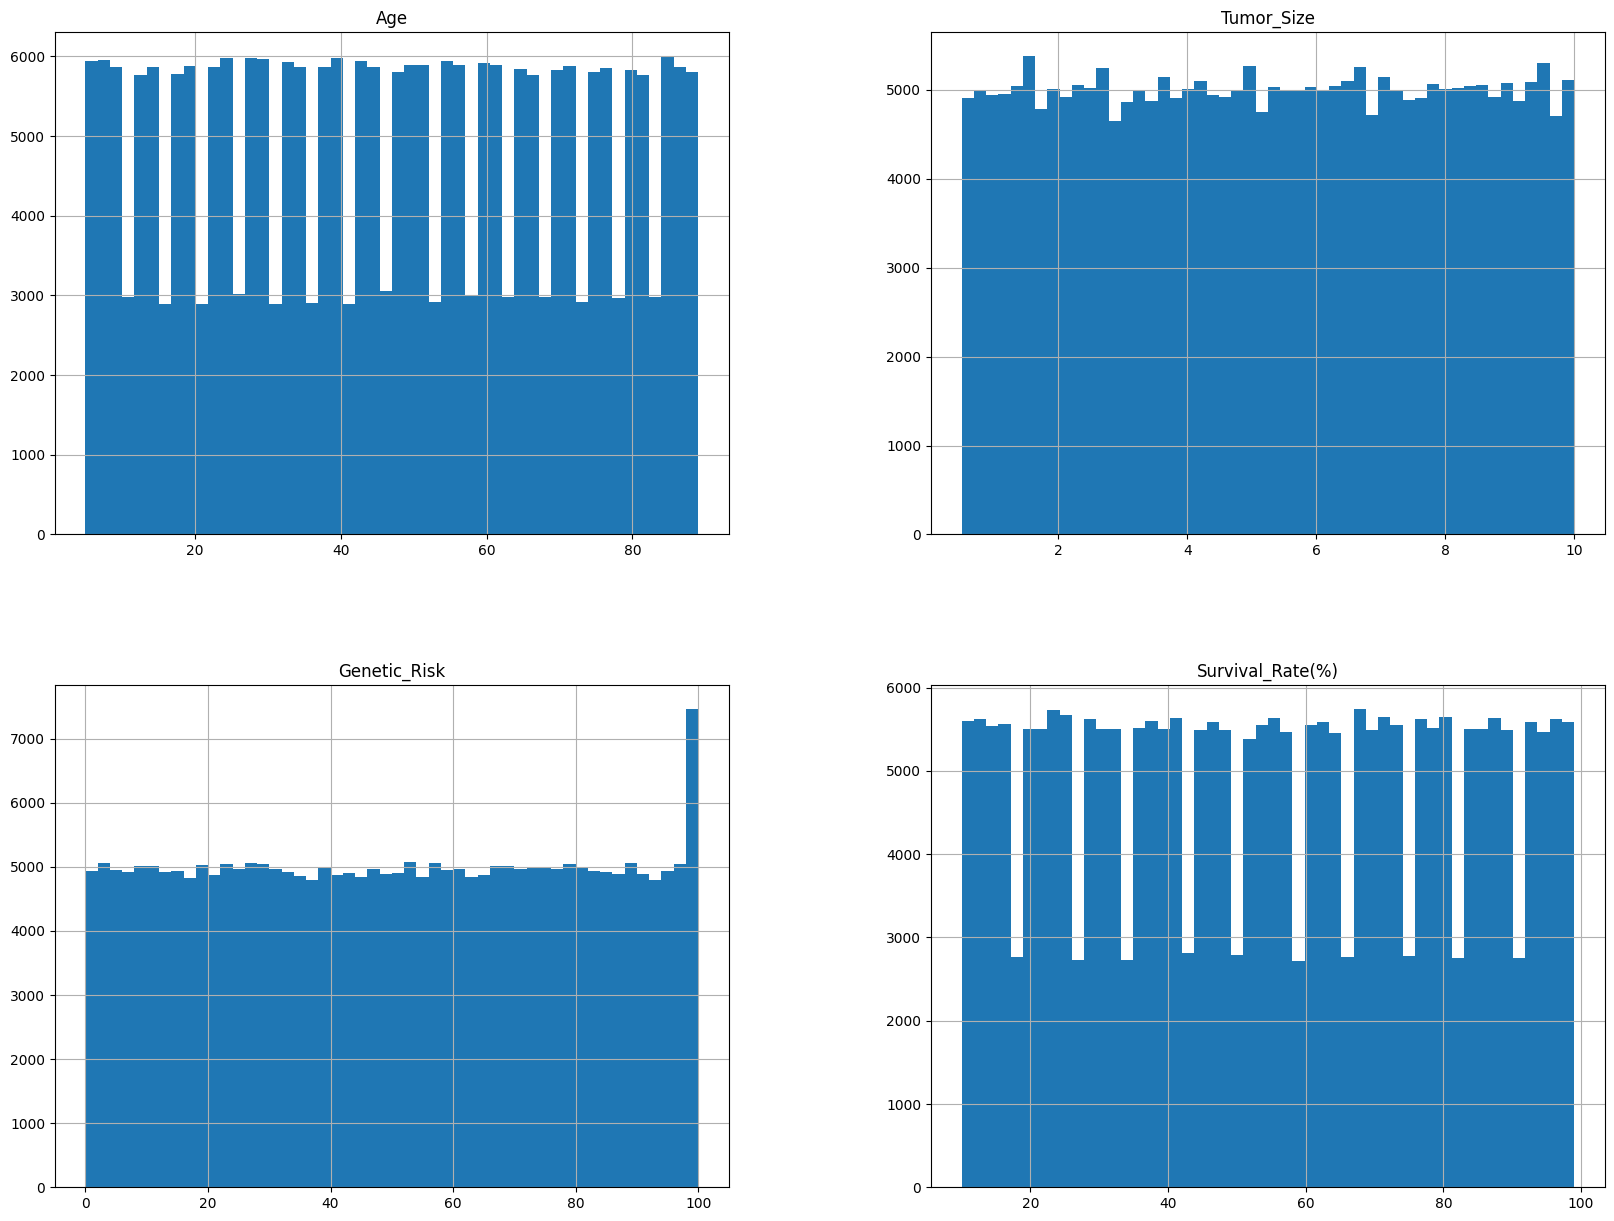

In [11]:
df.hist(bins=50, figsize=(20, 15))